# Trabalho Prático 1 - Compressão de Imagens 
### Isabela Ramos dos Santos - matrícula: 2023034757

Neste trabalho foi desenvolvido um método de compressão de imagens baseado na Transformada Discreta do Cosseno (DCT), quantização, ordenação zig-zag e codificação por comprimento de sequência (RLE).

## 1. Bibliotecas utilizadas

As bibliotecas utilizadas são responsáveis por:

- leitura e exibição das imagens;
- manipulação de matrizes;
- aplicação da DCT e da IDCT;
- operações matemáticas;
- armazenamento e comparação dos resultados.

A codificação e a decodificação dos dados comprimidos serão implementadas
manualmente.

In [55]:
import os                   # para leitura das imagens 
import struct                  

import cv2
import numpy as np                     
import matplotlib.pyplot as plt

from scipy import fftpack

## 2. Parâmetros do método

A imagem será processada em blocos de 8 × 8 pixels.

O tamanho de bloco foi escolhido porque blocos pequenos permitem representar
a imagem por regiões relativamente homogêneas e concentram a energia da DCT
em poucos coeficientes.

O parâmetro de quantização será alterado ao longo do notebook para demonstrar a relação entre tamanho do arquivo e qualidade da imagem reconstruída.

In [56]:
# colocados como const para poder experimentar outras formas e tambem porque o enunciado fala sobre teste em imagens diferentes
BLOCK_SIZE = 8

IMAGE_PATH = "lena.pgm"
#IMAGE_PATH = "cameraman.pgm"
#IMAGE_PATH = "baboon.pgm"
#IMAGE_PATH = "unequal.pgm"

In [57]:
import os
import cv2

# Separa nome e extensão
image_name, image_extension = os.path.splitext(IMAGE_PATH)

# Remove o caminho caso exista e pega somente o nome
base_name = os.path.basename(image_name)

# Nome do arquivo comprimido
COMPRESSED_PATH = base_name + ".compressed"

# Nome da imagem reconstruída
RECONSTRUCTED_PATH = base_name + "_reconstructed.pgm"

print("Imagem:", IMAGE_PATH)
print("Nome base:", base_name)
print("Arquivo comprimido:", COMPRESSED_PATH)
print("Imagem reconstruída:", RECONSTRUCTED_PATH)

Imagem: lena.pgm
Nome base: lena
Arquivo comprimido: lena.compressed
Imagem reconstruída: lena_reconstructed.pgm


## 3. Leitura da imagem

As imagens utilizadas no trabalho estão no formato PGM e são imagens
em escala de cinza.

A leitura é realizada com uma função pronta, conforme permitido pelo
enunciado.

In [58]:
img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(f"Não foi possível carregar: {IMAGE_PATH}")

print("Dimensões:", img.shape)
print("Tipo:", img.dtype)
print("Valor mínimo:", img.min())
print("Valor máximo:", img.max())

Dimensões: (512, 512)
Tipo: uint8
Valor mínimo: 25
Valor máximo: 245


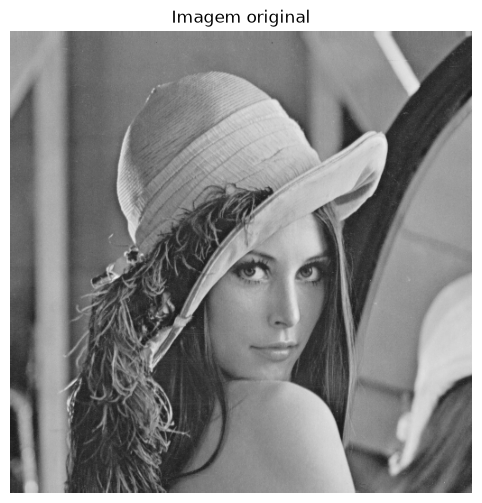

In [59]:
# exibe imagem 
plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem original")
plt.axis("off")
plt.show()

## 4. Métricas de qualidade

Duas métricas serão utilizadas para avaliar a reconstrução:

### RMSE

O erro quadrático médio representa a diferença entre a imagem original
e a imagem reconstruída.

### PSNR

O PSNR é calculado a partir do RMSE e será utilizado para avaliar a
qualidade da reconstrução. Quanto maior o PSNR, menor é o erro de
reconstrução.

In [60]:
def rmse(original, reconstructed):
    original = original.astype(np.float64)
    reconstructed = reconstructed.astype(np.float64)

    return np.sqrt(np.mean((original - reconstructed) ** 2))


def psnr(original, reconstructed):
    error = rmse(original, reconstructed)

    if error == 0:
        return float("inf")

    return 20 * np.log10(255.0 / error)

## 5. Transformada Discreta do Cosseno

A DCT será aplicada individualmente em cada bloco de 8 × 8 pixels.

A transformação muda a representação espacial do bloco para uma
representação em frequência.

In [61]:
def get_2D_dct(img):
    return fftpack.dct(fftpack.dct(img.T, norm='ortho').T, norm='ortho')

def get_2D_idct(coefficients):
    return fftpack.idct(fftpack.idct(coefficients.T, norm='ortho').T, norm='ortho')

## 6. Exemplo da DCT em um bloco

Antes de aplicar a compressão à imagem inteira, será analisado um único
bloco de 8 × 8 pixels.

In [62]:
sample_block = img[:8, :8].astype(np.float64)

print("Bloco original:")
print(np.round(sample_block, 1))

Bloco original:
[[162. 162. 162. 161. 162. 157. 163. 161.]
 [162. 162. 162. 161. 162. 157. 163. 161.]
 [162. 162. 162. 161. 162. 157. 163. 161.]
 [162. 162. 162. 161. 162. 157. 163. 161.]
 [162. 162. 162. 161. 162. 157. 163. 161.]
 [164. 164. 158. 155. 161. 159. 159. 160.]
 [160. 160. 163. 158. 160. 162. 159. 156.]
 [159. 159. 155. 157. 158. 159. 156. 157.]]


In [63]:
sample_dct = get_2D_dct(sample_block)

print("Bloco após DCT:")
print(np.round(sample_dct, 2))

Bloco após DCT:
[[ 1.2835e+03  4.7700e+00  3.2400e+00 -2.0000e-01  2.5000e-01 -5.5000e-01
  -4.5900e+00  5.6400e+00]
 [ 7.9500e+00 -7.9000e-01  5.5000e-01 -4.9300e+00  1.9600e+00  2.9800e+00
  -3.8000e+00  3.3200e+00]
 [-5.0300e+00 -3.0000e-01 -1.5500e+00  1.7200e+00 -6.8000e-01 -4.5000e-01
   1.8500e+00 -2.2000e+00]
 [ 2.2600e+00  1.1400e+00  1.7000e+00  9.2000e-01 -7.6000e-01 -1.3700e+00
   2.1000e-01  1.1400e+00]
 [-1.0000e+00 -1.1500e+00 -3.4000e-01 -1.3600e+00  1.7500e+00  1.1200e+00
  -1.4800e+00 -6.7000e-01]
 [ 1.2100e+00  4.6000e-01 -1.8000e+00 -1.1000e-01 -2.0100e+00  7.1000e-01
   1.6900e+00  7.6000e-01]
 [-1.7000e+00  2.6000e-01  3.1000e+00  1.6400e+00  1.6300e+00 -2.2500e+00
  -1.2000e+00 -9.0000e-01]
 [ 1.3300e+00 -4.2000e-01 -2.3800e+00 -1.5900e+00 -8.8000e-01  1.9700e+00
   5.5000e-01  6.5000e-01]]


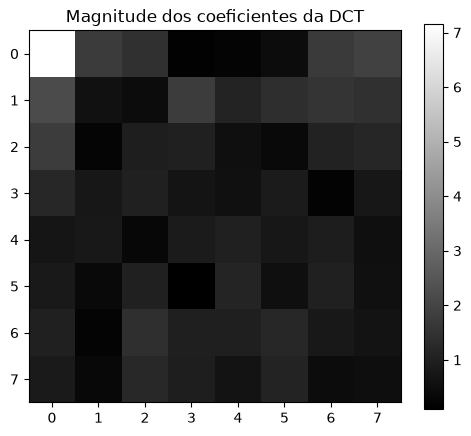

In [64]:
plt.figure(figsize=(6, 5))
plt.imshow(np.log1p(np.abs(sample_dct)), cmap="gray")
plt.colorbar()
plt.title("Magnitude dos coeficientes da DCT")
plt.show()

## 7. Quantização

Cada coeficiente da DCT é dividido por um valor da matriz de
quantização e posteriormente arredondado para valores inteiros. 

Coeficientes pequenos podem ser transformados em zero. Como os
coeficientes de alta frequência tendem a ser menores, essa etapa
produz muitos zeros, o que será aproveitado pela codificação RLE, produzindo uma fila com final de zeros.

In [65]:
QM_STANDARD = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 103, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float64)

In [66]:
def quantize(block, quantization_matrix):
    return np.round(block / quantization_matrix).astype(np.int32)


def dequantize(block, quantization_matrix):
    return block * quantization_matrix

In [67]:
sample_quantized = quantize(sample_dct, QM_STANDARD)

print("DCT:")
print(np.round(sample_dct, 1))

print("\nApós quantização:")
print(sample_quantized)       #note varios numeros virando zero

DCT:
[[ 1.2835e+03  4.8000e+00  3.2000e+00 -2.0000e-01  2.0000e-01 -6.0000e-01
  -4.6000e+00  5.6000e+00]
 [ 7.9000e+00 -8.0000e-01  6.0000e-01 -4.9000e+00  2.0000e+00  3.0000e+00
  -3.8000e+00  3.3000e+00]
 [-5.0000e+00 -3.0000e-01 -1.6000e+00  1.7000e+00 -7.0000e-01 -5.0000e-01
   1.8000e+00 -2.2000e+00]
 [ 2.3000e+00  1.1000e+00  1.7000e+00  9.0000e-01 -8.0000e-01 -1.4000e+00
   2.0000e-01  1.1000e+00]
 [-1.0000e+00 -1.1000e+00 -3.0000e-01 -1.4000e+00  1.7000e+00  1.1000e+00
  -1.5000e+00 -7.0000e-01]
 [ 1.2000e+00  5.0000e-01 -1.8000e+00 -1.0000e-01 -2.0000e+00  7.0000e-01
   1.7000e+00  8.0000e-01]
 [-1.7000e+00  3.0000e-01  3.1000e+00  1.6000e+00  1.6000e+00 -2.3000e+00
  -1.2000e+00 -9.0000e-01]
 [ 1.3000e+00 -4.0000e-01 -2.4000e+00 -1.6000e+00 -9.0000e-01  2.0000e+00
   6.0000e-01  7.0000e-01]]

Após quantização:
[[80  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0 

## 8. Varredura em zig-zag

Após a quantização, os coeficientes são reorganizados por uma varredura
em zig-zag.

Essa ordem percorre os coeficientes partindo das baixas frequências
em direção às altas frequências.

Como os coeficientes de alta frequência tendem a ser zerados pela
quantização, a varredura concentra os zeros no final do vetor.

Isso prepara os dados para a próxima etapa: a codificação RLE.

In [68]:
ZIGZAG_INDEXES = [
    (0,0), (0,1), (1,0), (2,0), (1,1), (0,2), (0,3), (1,2),
    (2,1), (3,0), (4,0), (3,1), (2,2), (1,3), (0,4), (0,5),
    (1,4), (2,3), (3,2), (4,1), (5,0), (6,0), (5,1), (4,2),
    (3,3), (2,4), (1,5), (0,6), (0,7), (1,6), (2,5), (3,4),
    (4,3), (5,2), (6,1), (7,0), (7,1), (6,2), (5,3), (4,4),
    (3,5), (2,6), (1,7), (2,7), (3,6), (4,5), (5,4), (6,3),
    (7,2), (7,3), (6,4), (5,5), (4,6), (3,7), (4,7), (5,6),
    (6,5), (7,4), (7,5), (6,6), (5,7), (6,7), (7,6), (7,7)
]

In [69]:
def block_to_zigzag(block):
    return np.array(
        [block[row, col] for row, col in ZIGZAG_INDEXES],
        dtype=np.int32
    )

In [70]:
sample_zigzag = block_to_zigzag(sample_quantized)

print("Coeficientes após varredura zig-zag:")
print(sample_zigzag)

Coeficientes após varredura zig-zag:
[80  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]


## 9. Codificação por comprimento de sequência (RLE)

Depois da varredura zig-zag, os zeros consecutivos são representados
por uma única informação contendo a quantidade de zeros e o próximo
valor diferente de zero.

Por exemplo:

[5, 2, 0, 0, 0, 7, 0, 0, 0, 0]

pode ser representado como:

[(0, 5), (0, 2), (3, 7), (4, EOB)]

Essa representação reduz a quantidade de dados quando existem longas
sequências de zeros.

In [71]:
def rle_encode(vector):
    encoded = []
    zero_count = 0

    for value in vector:

        if value == 0:
            zero_count += 1

        else:
            encoded.append((zero_count, int(value)))
            zero_count = 0

    encoded.append(("EOB", 0))

    return encoded

In [72]:
sample_rle = rle_encode(sample_zigzag)

print("Resultado da codificação RLE:")
print(sample_rle)

Resultado da codificação RLE:
[(0, 80), (1, 1), ('EOB', 0)]


## 10. Decodificação RLE

Para reconstruir a imagem, o processo de RLE deve ser invertido.

Cada par `(n, valor)` representa `n` zeros seguidos pelo valor informado.
Ao encontrar `EOB`, os elementos restantes do bloco são preenchidos
com zeros.

In [73]:
def rle_decode(encoded):
    decoded = []

    for item in encoded:

        if item[0] == "EOB":
            break

        zero_count, value = item

        decoded.extend([0] * zero_count)
        decoded.append(value)

    while len(decoded) < 64:
        decoded.append(0)

    return np.array(decoded[:64], dtype=np.int32)

## 11. Inversão da varredura zig-zag

Após a decodificação RLE, temos novamente os 64 coeficientes em forma
de vetor.

A função abaixo reorganiza esses coeficientes em uma matriz 8 × 8,
recuperando a disposição utilizada antes da varredura zig-zag.

In [74]:
decoded_zigzag = rle_decode(sample_rle)
def zigzag_to_block(vector):
    block = np.zeros((8, 8), dtype=np.int32)

    for index, (row, col) in enumerate(ZIGZAG_INDEXES):
        block[row, col] = vector[index]

    return block

reconstructed_quantized = zigzag_to_block(decoded_zigzag)

print("Matriz recuperada:")
print(reconstructed_quantized)

print("\nMatriz original:")
print(sample_quantized)

print(
    "\nAs matrizes são iguais?",
    np.array_equal(sample_quantized, reconstructed_quantized)
)

Matriz recuperada:
[[80  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]]

Matriz original:
[[80  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]]

As matrizes são iguais? True


## 12. Teste completo de um bloco

Antes de processar a imagem inteira, será testado o caminho completo
de um único bloco:

Imagem → DCT → Quantização → Zig-zag → RLE

e posteriormente:

RLE → Zig-zag inverso → Desquantização → IDCT → Imagem reconstruída.

In [75]:
dequantized_sample = dequantize(reconstructed_quantized, QM_STANDARD)

reconstructed_sample = get_2D_idct(dequantized_sample) + 128
reconstructed_sample = np.clip(reconstructed_sample, 0, 255)

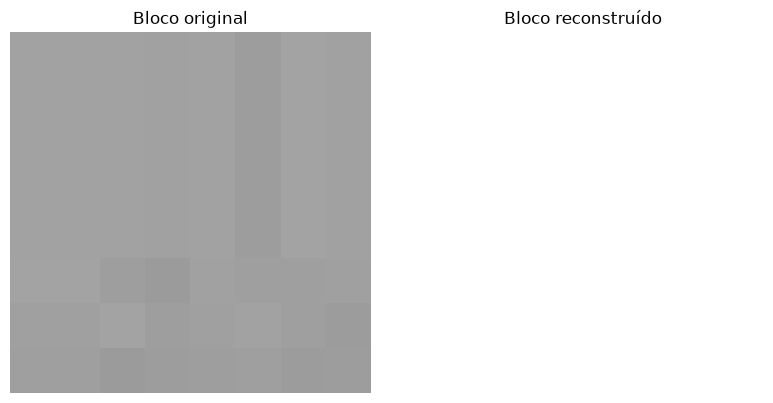

In [76]:
# visualizaçao 
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(sample_block, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Bloco original")
axes[0].axis("off")

axes[1].imshow(reconstructed_sample, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Bloco reconstruído")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 13. Codificação da imagem

A partir deste ponto, o mesmo processo aplicado ao bloco de exemplo
será aplicado a todos os blocos 8 × 8 da imagem.

Para cada bloco:

1. deslocamos os valores em -128;
2. aplicamos a DCT;
3. quantizamos os coeficientes;
4. realizamos a varredura zig-zag;
5. aplicamos RLE;
6. armazenamos os dados codificados.

Os dados serão posteriormente gravados em um arquivo binário próprio.

In [77]:
def crop_to_block_size(image, block_size=8):
    height, width = image.shape

    new_height = (height // block_size) * block_size
    new_width = (width // block_size) * block_size

    return image[:new_height, :new_width]

### Imagens com dimensões que não são múltiplas de 8

Como o algoritmo trabalha com blocos 8 × 8, imagens cujas dimensões
não sejam múltiplas de 8 terão suas bordas ajustadas para o maior
tamanho possível divisível por 8.

Essa escolha evita a necessidade de preencher artificialmente a imagem
e mantém todos os blocos com o mesmo tamanho.

## 14. Formato do arquivo comprimido

Foi desenvolvido um formato binário próprio para armazenar os dados
produzidos pelo método de compressão.

Cada elemento da codificação RLE é armazenado utilizando:

- 1 byte para a quantidade de zeros;
- 2 bytes para o valor do coeficiente quantizado.

O valor 255 no campo de quantidade de zeros é reservado para indicar
o final do bloco (EOB - End Of Block).

Como cada bloco possui apenas 64 coeficientes, um byte é suficiente
para representar a quantidade de zeros.

Os coeficientes são armazenados como inteiros de 16 bits com sinal,
permitindo representar valores positivos e negativos.

Além dos dados RLE, o arquivo possui um cabeçalho contendo as
informações necessárias para sua decodificação.

In [78]:
import struct

# Identificador do nosso formato de arquivo
MAGIC = b"ICMP"

# Tamanho dos blocos usados na DCT
BLOCK_SIZE = 8

# Marcador utilizado para indicar o fim de um bloco RLE
EOB_MARKER = 255

def encode_rle_block(rle_data):
    """
    Converte uma lista RLE completa em bytes.
    """

    binary_data = bytearray()

    for zero_count, value in rle_data:

        if zero_count == "EOB":
            binary_data.extend(
                struct.pack("<Bh", EOB_MARKER, 0)
            )

        else:
            binary_data.extend(
                struct.pack("<Bh", zero_count, value)
            )

    return bytes(binary_data)

In [79]:
def decode_rle_block(binary_data):
    """
    Converte bytes de um bloco RLE de volta para
    uma lista de pares (zeros, valor).
    """

    rle_data = []

    record_size = 3

    for position in range(0, len(binary_data), record_size):

        record = binary_data[position:position + record_size]

        zero_count, value = struct.unpack(
            "<Bh",
            record
        )

        if zero_count == EOB_MARKER:
            rle_data.append(("EOB", 0))
            break

        rle_data.append((zero_count, value))

    return rle_data

In [80]:
test_rle = [
    (0, 52),
    (0, 4),
    (3, -2),
    (2, 7),
    ("EOB", 0)
]

encoded = encode_rle_block(test_rle)

print("RLE:")
print(test_rle)

print("\nBytes:")
print(list(encoded))

print("\nTamanho:")
print(len(encoded), "bytes")

decoded = decode_rle_block(encoded)

print("RLE original:")
print(test_rle)

print("\nRLE decodificado:")
print(decoded)

print(
    "\nA codificação é reversível?",
    test_rle == decoded
)

RLE:
[(0, 52), (0, 4), (3, -2), (2, 7), ('EOB', 0)]

Bytes:
[0, 52, 0, 0, 4, 0, 3, 254, 255, 2, 7, 0, 255, 0, 0]

Tamanho:
15 bytes
RLE original:
[(0, 52), (0, 4), (3, -2), (2, 7), ('EOB', 0)]

RLE decodificado:
[(0, 52), (0, 4), (3, -2), (2, 7), ('EOB', 0)]

A codificação é reversível? True


## 15. Formato do cabeçalho do arquivo comprimido

O arquivo comprimido será formado por duas partes:

1. um cabeçalho contendo as informações necessárias para a decodificação;
2. os dados comprimidos dos blocos da imagem.

O cabeçalho terá o seguinte formato:

| Campo | Tamanho |
|---|---:|
| Identificador (`MAGIC`) | 4 bytes |
| Largura da imagem | 4 bytes |
| Altura da imagem | 4 bytes |
| Tamanho do bloco | 1 byte |
| Matriz de quantização 8×8 | 128 bytes |

A matriz de quantização possui 64 valores. Cada valor será armazenado
como um inteiro sem sinal de 16 bits (`uint16`), utilizando 2 bytes.

Portanto, o cabeçalho terá:

**4 + 4 + 4 + 1 + 128 = 141 bytes.**

A vantagem de armazenar a matriz no próprio arquivo é que o processo
de descompressão poderá utilizar exatamente a mesma matriz utilizada
durante a compressão.

In [81]:
def encode_header(width, height, padded_width,
    padded_height, block_size, QM):
    # Garante que a matriz possui 8x8 elementos
    QM = np.asarray(QM, dtype=np.uint16)

    if QM.shape != (8, 8):
        raise ValueError("A matriz de quantização deve ter tamanho 8x8.")
    
    header = struct.pack(
        "<4sIIIIB",
        MAGIC,
        width,
        height,
        padded_width,
        padded_height,
        block_size
    )
    
    # Converte a matriz 8x8 em uma sequência de 64 valores
    qm_bytes = QM.tobytes()
    
    return header + qm_bytes

def decode_header(binary_data):

    fixed_header_size = struct.calcsize("<4sIIIIB")
    
    magic, width, height, padded_width, padded_height, block_size = struct.unpack(
        "<4sIIIIB",
        binary_data[:fixed_header_size]
    )
    
    if magic != MAGIC:
        raise ValueError("Arquivo não pertence ao formato ICMP.")
    
    # Os próximos 128 bytes correspondem à matriz de quantização
    qm_size = 8 * 8 * 2
    
    qm_start = fixed_header_size
    qm_end = qm_start + qm_size
    
    qm_bytes = binary_data[
        qm_start:qm_end
    ]
    
    QM = np.frombuffer(
        qm_bytes,
        dtype=np.uint16
    ).reshape((8, 8))
    
    return (
        width,
        height,
        padded_width,
        padded_height,
        block_size,
        QM
    )

In [82]:
width = 512
height = 512
padded_width = 512
padded_height = 512
block_size = 8

header = encode_header(
    width,
    height,
    padded_width,
    padded_height,
    block_size,
    QM_STANDARD
)

print("Tamanho do cabeçalho:", len(header), "bytes")

(
    decoded_width,
    decoded_height,
    decoded_padded_width,
    decoded_padded_height,
    decoded_block_size,
    decoded_QM
) = decode_header(header)

print("Largura:", decoded_width)
print("Altura:", decoded_height)
print("Largura com padding:", decoded_padded_width)
print("Altura com padding:", decoded_padded_height)
print("Tamanho do bloco:", decoded_block_size)

print("\nMatriz de quantização:")
print(decoded_QM)

Tamanho do cabeçalho: 149 bytes
Largura: 512
Altura: 512
Largura com padding: 512
Altura com padding: 512
Tamanho do bloco: 8

Matriz de quantização:
[[ 16  11  10  16  24  40  51  61]
 [ 12  12  14  19  26  58  60  55]
 [ 14  13  16  24  40  57  69  56]
 [ 14  17  22  29  51  87 103  62]
 [ 18  22  37  56  68 109 103  77]
 [ 24  35  55  64  81 104 113  92]
 [ 49  64  78  87 103 121 120 101]
 [ 72  92  95  98 112 100 103  99]]


In [83]:
width = 512
height = 512
padded_width = 512
padded_height = 512
block_size = 8

header = encode_header(
    width,
    height,
    padded_width,
    padded_height,
    block_size,
    QM_STANDARD
)

print("Tamanho do cabeçalho:", len(header), "bytes")

(
    decoded_width,
    decoded_height,
    decoded_padded_width,
    decoded_padded_height,
    decoded_block_size,
    decoded_QM
) = decode_header(header)

print("Largura:", decoded_width)
print("Altura:", decoded_height)
print("Largura com padding:", decoded_padded_width)
print("Altura com padding:", decoded_padded_height)
print("Tamanho do bloco:", decoded_block_size)

print("\nMatriz de quantização:")
print(decoded_QM)

Tamanho do cabeçalho: 149 bytes
Largura: 512
Altura: 512
Largura com padding: 512
Altura com padding: 512
Tamanho do bloco: 8

Matriz de quantização:
[[ 16  11  10  16  24  40  51  61]
 [ 12  12  14  19  26  58  60  55]
 [ 14  13  16  24  40  57  69  56]
 [ 14  17  22  29  51  87 103  62]
 [ 18  22  37  56  68 109 103  77]
 [ 24  35  55  64  81 104 113  92]
 [ 49  64  78  87 103 121 120 101]
 [ 72  92  95  98 112 100 103  99]]


In [84]:
def run_length_encoding(vector_1d):
    """
    Codifica um vetor usando Run-Length Encoding (RLE).

    Para cada valor diferente de zero, armazenamos:
    (quantidade_de_zeros_anteriores, valor)

    Ao final do bloco, adicionamos:
    ("EOB", 0)

    EOB = End Of Block
    """

    rle = []
    zero_count = 0

    for value in vector_1d:

        if value == 0:
            zero_count += 1

        else:
            rle.append(
                (zero_count, int(value))
            )
            zero_count = 0

    # Marca o final do bloco
    rle.append(
        ("EOB", 0)
    )

    return rle

In [85]:
def compress_image(img_gray, output_path, QM):
    """
    Comprime uma imagem em escala de cinza utilizando:

    DCT -> quantização -> zig-zag -> RLE

    O resultado é salvo em um arquivo binário próprio.
    """

    h, w = img_gray.shape

    # Calcula quanto precisamos adicionar para chegar
    # ao próximo múltiplo de 8.
    pad_h = (BLOCK_SIZE - h % BLOCK_SIZE) % BLOCK_SIZE
    pad_w = (BLOCK_SIZE - w % BLOCK_SIZE) % BLOCK_SIZE

    # Adiciona padding replicando os pixels da borda.
    img_padded = np.pad(
        img_gray,
        ((0, pad_h), (0, pad_w)),
        mode="edge"
    )

    h_padded, w_padded = img_padded.shape

    # Cria o cabeçalho usando as dimensões originais
    # e as dimensões após o padding.
    header = encode_header(
        w,
        h,
        w_padded,
        h_padded,
        BLOCK_SIZE,
        QM
    )

    compressed_data = bytearray(header)

    # Processa todos os blocos 8x8
    for y in range(0, h_padded, BLOCK_SIZE):
        for x in range(0, w_padded, BLOCK_SIZE):

            block = img_padded[
                y:y + BLOCK_SIZE,
                x:x + BLOCK_SIZE
            ]

            # Centralização dos valores
            block_shifted = (
                block.astype(np.float64) - 128.0
            )

            # DCT
            dct_block = get_2D_dct(block_shifted)

            # Quantização
            quantized = np.round(
                dct_block / QM
            ).astype(np.int16)

            # Zig-zag
            zigzag_vector = block_to_zigzag(
                quantized
            )

            # RLE
            rle_data = run_length_encoding(
                zigzag_vector
            )

            # Converte para bytes
            compressed_data.extend(
                encode_rle_block(rle_data)
            )

    # Salva o arquivo comprimido
    with open(output_path, "wb") as file:
        file.write(compressed_data)

    return h, w, h_padded, w_padded

In [86]:
img = cv2.imread(
    IMAGE_PATH,
    cv2.IMREAD_GRAYSCALE
)

In [87]:
print("Dimensões:", img.shape)
print("Tipo:", img.dtype)

h, w, h_padded, w_padded = compress_image(
    img,
    COMPRESSED_PATH,
    QM_STANDARD
)

print("Arquivo criado:", COMPRESSED_PATH)

print(
    "Dimensões originais:",
    w,
    "x",
    h
)

print(
    "Dimensões processadas:",
    w_padded,
    "x",
    h_padded
)

Dimensões: (512, 512)
Tipo: uint8
Arquivo criado: lena.compressed
Dimensões originais: 512 x 512
Dimensões processadas: 512 x 512


In [88]:
import os

print(
    "Arquivo existe?",
    os.path.exists(COMPRESSED_PATH)
)

file_size = os.path.getsize(COMPRESSED_PATH)

print(
    "Tamanho do arquivo comprimido:",
    file_size,
    "bytes"
)

Arquivo existe? True
Tamanho do arquivo comprimido: 97967 bytes


In [89]:
original_size = h * w
compressed_size = os.path.getsize(COMPRESSED_PATH)

compression_ratio = (original_size / compressed_size)

bits_per_pixel = (
    compressed_size * 8
) / (h * w)

print("Tamanho original:", original_size, "bytes")
print("Tamanho comprimido:", compressed_size, "bytes")
print(f"Taxa de compressão: {compression_ratio:.2f}")
print(f"Bits por pixel: {bits_per_pixel:.2f}")

Tamanho original: 262144 bytes
Tamanho comprimido: 97967 bytes
Taxa de compressão: 2.68
Bits por pixel: 2.99


In [90]:
percentage = (
    compressed_size / original_size
) * 100

print(
    f"O arquivo comprimido possui {percentage:.2f}% "
    "do tamanho original."
)

O arquivo comprimido possui 37.37% do tamanho original.


In [91]:
def decompress_image(input_path):
    """
    Lê um arquivo .compressed e reconstrói a imagem.
    """

    # Abre o arquivo binário
    with open(input_path, "rb") as file:
        binary_data = file.read()

    # Tamanho da parte fixa do cabeçalho
    fixed_header_size = struct.calcsize(
        "<4sIIIIB"
    )

    # Tamanho total do cabeçalho:
    # 21 bytes fixos + 128 bytes da matriz
    header_size = fixed_header_size + (8 * 8 * 2)

    # Decodifica o cabeçalho
    (
        width,
        height,
        padded_width,
        padded_height,
        block_size,
        QM
    ) = decode_header(
        binary_data[:header_size]
    )

    # Cria a imagem reconstruída com as dimensões
    # utilizadas durante a compressão
    reconstructed_padded = np.zeros(
        (padded_height, padded_width),
        dtype=np.float64
    )

    # Posição atual nos dados RLE
    position = header_size

    # Processa cada bloco 8x8
    for y in range(0, padded_height, block_size):
        for x in range(0, padded_width, block_size):

            # Cada registro RLE possui 3 bytes.
            # Lemos registros até encontrar o EOB.
            block_bytes = bytearray()

            while True:
                if position >= len(binary_data):
                    break
                record = binary_data[position: position + 3]
                if len(record) < 3:
                    break
                block_bytes.extend(record)
                position += 3
                zero_count = record[0]
                if zero_count == EOB_MARKER:
                    break

            # Converte os bytes para RLE
            rle_data = decode_rle_block(
                bytes(block_bytes)
            )

            # Reconstrói o vetor zig-zag
            quantized_vector = np.zeros(
                64,
                dtype=np.int16
            )

            index = 0

            for zero_count, value in rle_data:

                if zero_count == "EOB":
                    break

                index += zero_count

                quantized_vector[index] = value

                index += 1

            # Reconstrói a matriz 8x8
            quantized_block = np.zeros(
                (8, 8),
                dtype=np.float64
            )

            for i, (row, col) in enumerate(
                ZIGZAG_INDEXES
            ):
                quantized_block[row, col] = (
                    quantized_vector[i]
                )

            # Desquantização
            dequantized = (
                quantized_block * QM
            )

            # IDCT
            block_reconstructed = get_2D_idct(
                dequantized
            )

            # Volta para a faixa original
            block_reconstructed += 128.0

            # Coloca o bloco na imagem
            reconstructed_padded[
                y:y + block_size,
                x:x + block_size
            ] = block_reconstructed

    # Remove o padding.
    # Assim, a imagem volta a ter exatamente
    # as dimensões originais.
    reconstructed = reconstructed_padded[
        :height,
        :width
    ]

    # Garante valores válidos de imagem
    reconstructed = np.clip(
        reconstructed,
        0,
        255
    )

    return reconstructed.astype(np.uint8)

In [92]:
img_reconstructed = decompress_image(
    COMPRESSED_PATH
)

print(
    "Imagem reconstruída:",
    img_reconstructed.shape
)

Imagem reconstruída: (512, 512)


In [93]:
cv2.imwrite(
    RECONSTRUCTED_PATH,
    img_reconstructed
)

print(
    "Imagem reconstruída salva em:",
    RECONSTRUCTED_PATH
)

Imagem reconstruída salva em: lena_reconstructed.pgm


## 17. Comparação visual e mapa de erro

Para analisar visualmente o efeito da compressão, são apresentadas
simultaneamente a imagem original, a imagem reconstruída e o mapa
de erro absoluto.

O erro absoluto é calculado pixel a pixel por:


$E(x,y) = |I(x,y) - \hat{I}(x,y)|$


onde $(I(x,y)$ representa a imagem original e $\hat{I}(x,y)$
representa a imagem reconstruída.

No mapa de erro, regiões com valores próximos de zero indicam pouca
diferença entre as imagens, enquanto regiões com valores maiores
indicam maior alteração causada pelo processo de quantização.

Essa visualização permite relacionar diretamente a perda de qualidade
observada na imagem com as regiões onde ocorreram maiores erros.

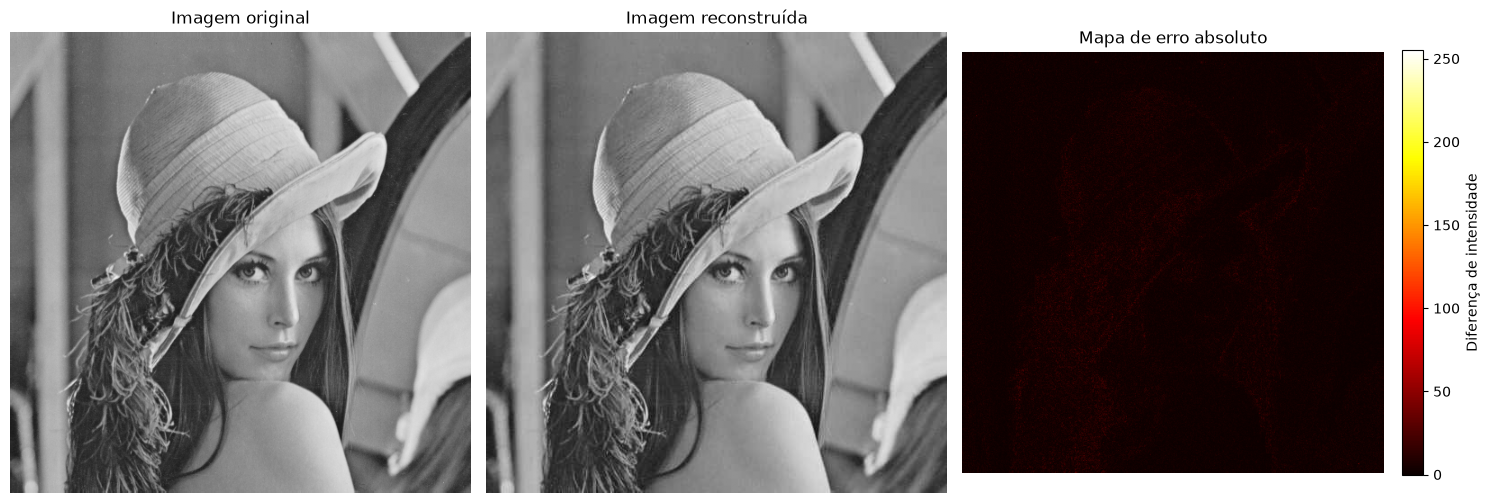

RESULTADOS DA COMPRESSÃO
Imagem: lena.pgm
Bytes antes da compressão : 262,144 bytes
Bytes depois da compressão: 97,967 bytes

Taxa de compressão: 2.68
Critério de compressão: OK (>= 2)

RMSE: 4.17
PSNR: 35.72 dB
Critério de PSNR: OK (>= 33 dB)

Resultado geral: BOM


In [94]:
error = np.abs(
    img.astype(np.float64) -
    img_reconstructed.astype(np.float64)
)

rmse_value = rmse(
    img_reconstructed.astype(np.float64),
    img.astype(np.float64)
)

psnr_value = psnr(
    img_reconstructed.astype(np.float64),
    img.astype(np.float64)
)

original_size = h * w

compressed_size = os.path.getsize(
    COMPRESSED_PATH
)

compression_ratio = (
    original_size / compressed_size
)

# Critérios definidos no enunciado
psnr_ok = psnr_value >= 33
compression_ok = compression_ratio >= 2

if psnr_ok and compression_ok:
    result_status = "BOM"
else:
    result_status = "RUIM"


# ------------------------------------------------------------
# Visualização
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

# Original
axes[0].imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[0].set_title("Imagem original")
axes[0].axis("off")


# Reconstruída
axes[1].imshow(
    img_reconstructed,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[1].set_title("Imagem reconstruída")
axes[1].axis("off")


# Erro
im = axes[2].imshow(
    error,
    cmap="hot",
    vmin=0,
    vmax=255
)

axes[2].set_title("Mapa de erro absoluto")
axes[2].axis("off")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Diferença de intensidade"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Métricas
# ------------------------------------------------------------

print("=" * 60)
print("RESULTADOS DA COMPRESSÃO")
print("=" * 60)

print(f"Imagem: {IMAGE_PATH}")

print(
    f"Bytes antes da compressão : "
    f"{original_size:,} bytes"
)

print(
    f"Bytes depois da compressão: "
    f"{compressed_size:,} bytes"
)

print(
    f"\nTaxa de compressão: "
    f"{compression_ratio:.2f}"
)

if compression_ok:
    print("Critério de compressão: OK (>= 2)")
else:
    print("Critério de compressão: RUIM (< 2)")

print(f"\nRMSE: {rmse_value:.2f}")

print(f"PSNR: {psnr_value:.2f} dB")

if psnr_ok:
    print("Critério de PSNR: OK (>= 33 dB)")
else:
    print("Critério de PSNR: RUIM (< 33 dB)")

print(f"\nResultado geral: {result_status}")

print("=" * 60)

# 18. Análise do efeito da quantização

A intensidade da quantização influencia diretamente a quantidade de
informação descartada.

Para analisar esse efeito, serão utilizadas diferentes matrizes de
quantização.

Espera-se que uma quantização mais agressiva produza mais coeficientes
iguais a zero, facilitando a codificação RLE e reduzindo o tamanho do
arquivo. Em contrapartida, a imagem reconstruída tende a apresentar
maior erro e menor PSNR.

O objetivo deste experimento é observar empiricamente esse compromisso
entre taxa de compressão e qualidade.

In [95]:
QM_SOFT = np.maximum(
    np.round(QM_STANDARD * 0.5),
    1
).astype(np.uint16)

QM_STANDARD_LEVEL = QM_STANDARD.copy()

QM_STRONG = np.maximum(
    np.round(QM_STANDARD * 2.0),
    1
).astype(np.uint16)

QM_EXTREME = np.maximum(
    np.round(QM_STANDARD * 4.0),
    1
).astype(np.uint16)
quantization_matrices = {
    "Suave": QM_SOFT,
    "Padrão": QM_STANDARD_LEVEL,
    "Forte": QM_STRONG,
    "Extrema": QM_EXTREME
}

In [96]:
print("Matrizes de quantização criadas:")
print("Suave")
print(QM_SOFT)

print("\nPadrão")
print(QM_STANDARD_LEVEL)

print("\nForte")
print(QM_STRONG)

print("\nExtrema")
print(QM_EXTREME)

Matrizes de quantização criadas:
Suave
[[ 8  6  5  8 12 20 26 30]
 [ 6  6  7 10 13 29 30 28]
 [ 7  6  8 12 20 28 34 28]
 [ 7  8 11 14 26 44 52 31]
 [ 9 11 18 28 34 54 52 38]
 [12 18 28 32 40 52 56 46]
 [24 32 39 44 52 60 60 50]
 [36 46 48 49 56 50 52 50]]

Padrão
[[ 16.  11.  10.  16.  24.  40.  51.  61.]
 [ 12.  12.  14.  19.  26.  58.  60.  55.]
 [ 14.  13.  16.  24.  40.  57.  69.  56.]
 [ 14.  17.  22.  29.  51.  87. 103.  62.]
 [ 18.  22.  37.  56.  68. 109. 103.  77.]
 [ 24.  35.  55.  64.  81. 104. 113.  92.]
 [ 49.  64.  78.  87. 103. 121. 120. 101.]
 [ 72.  92.  95.  98. 112. 100. 103.  99.]]

Forte
[[ 32  22  20  32  48  80 102 122]
 [ 24  24  28  38  52 116 120 110]
 [ 28  26  32  48  80 114 138 112]
 [ 28  34  44  58 102 174 206 124]
 [ 36  44  74 112 136 218 206 154]
 [ 48  70 110 128 162 208 226 184]
 [ 98 128 156 174 206 242 240 202]
 [144 184 190 196 224 200 206 198]]

Extrema
[[ 64  44  40  64  96 160 204 244]
 [ 48  48  56  76 104 232 240 220]
 [ 56  52  64  96 160 22

## 19. Avaliação das diferentes quantizações

Para cada matriz serão registrados:

- tamanho do arquivo comprimido;
- taxa de compressão;
- RMSE;
- PSNR.

Assim será possível comparar quantitativamente os efeitos da
quantização.

In [97]:
def evaluate_quantization_matrix(img_gray,QM,name):
    output_path = f"teste_{name}.compressed"
    # Compressão
    h, w, h_padded, w_padded = compress_image(
        img_gray,
        output_path,
        QM
    )

    # Descompressão
    reconstructed = decompress_image(
        output_path
    )

    # Métricas de qualidade
    rmse_value = rmse(
        reconstructed.astype(np.float64),
        img_gray.astype(np.float64)
    )

    psnr_value = psnr(
        reconstructed.astype(np.float64),
        img_gray.astype(np.float64)
    )

    # Tamanho do arquivo
    compressed_size = os.path.getsize(
        output_path
    )

    # Consideramos os pixels da imagem original
    original_size = h * w

    # Taxa de compressão
    compression_ratio = (
        original_size / compressed_size
    )

    # Bits por pixel
    bits_per_pixel = (
        compressed_size * 8
    ) / (h * w)

    return {
        "Matriz": name,
        "Tamanho (bytes)": compressed_size,
        "Taxa de compressão": compression_ratio,
        "Bits por pixel": bits_per_pixel,
        "RMSE": rmse_value,
        "PSNR (dB)": psnr_value
    }

In [98]:
results = []

for name, QM in quantization_matrices.items():

    result = evaluate_quantization_matrix(
        img,
        QM,
        name
    )

    results.append(result)

In [99]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df

,Matriz,Tamanho (bytes),Taxa de compressão,Bits por pixel,RMSE,PSNR (dB)
0,Suave,146102,1.794253,4.458679,3.313601,37.724800
1,Padrão,97967,2.675840,2.989716,4.171934,35.724054
2,Forte,67238,3.898748,2.051941,5.293539,33.655881
3,Extrema,47498,5.519053,1.449524,7.006218,31.221131


In [100]:
results_df["Compressão >= 2"] = (
    results_df["Taxa de compressão"] >= 2
)

results_df["PSNR >= 33 dB"] = (
    results_df["PSNR (dB)"] >= 33
)

results_df["Atende aos dois critérios"] = (
    results_df["Compressão >= 2"] &
    results_df["PSNR >= 33 dB"]
)

results_df

,Matriz,Tamanho (bytes),Taxa de compressão,Bits por pixel,RMSE,PSNR (dB),Compressão >= 2,PSNR >= 33 dB,Atende aos dois critérios
0,Suave,146102,1.794253,4.458679,3.313601,37.724800,False,True,False
1,Padrão,97967,2.675840,2.989716,4.171934,35.724054,True,True,True
2,Forte,67238,3.898748,2.051941,5.293539,33.655881,True,True,True
3,Extrema,47498,5.519053,1.449524,7.006218,31.221131,True,False,False


# 21. Avaliação nas imagens do trabalho

O método será avaliado nas quatro imagens fornecidas:

- baboon.pgm
- cameraman.pgm
- lena.pgm
- unequal.pgm

Para essa comparação será utilizada a matriz de quantização definida
como configuração principal do método.

In [101]:
IMAGE_PATHS = [
    "baboon.pgm",
    "cameraman.pgm",
    "lena.pgm",
    "unequal.pgm"
]

In [102]:
def classify_result(compression_ratio, psnr_value):

    compression_status = (
        "BOM"
        if compression_ratio >= 2
        else "RUIM"
    )

    psnr_status = (
        "BOM"
        if psnr_value >= 33
        else "RUIM"
    )

    overall_status = (
        "BOM"
        if compression_ratio >= 2 and psnr_value >= 33
        else "RUIM"
    )

    return (
        compression_status,
        psnr_status,
        overall_status
    )

In [103]:
all_results = []

for image_path in IMAGE_PATHS:
    img_test = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if img_test is None:
        raise FileNotFoundError(
            f"Não foi possível encontrar {image_path}"
        )

    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    for matrix_name, QM in quantization_matrices.items():

        output_path = (
            f"{image_name}_{matrix_name}.compressed"
        )

        # Compressão
        h_test, w_test, h_padded, w_padded = (
            compress_image(
                img_test,
                output_path,
                QM
            )
        )

        # Descompressão
        reconstructed_test = decompress_image(
            output_path
        )

        # RMSE
        rmse_value = rmse(
            reconstructed_test.astype(np.float64),
            img_test.astype(np.float64)
        )

        # PSNR
        psnr_value = psnr(
            reconstructed_test.astype(np.float64),
            img_test.astype(np.float64)
        )

        # Tamanhos
        original_size = h_test * w_test
        compressed_size = os.path.getsize(
            output_path
        )

        # Taxa de compressão
        compression_ratio = (
            original_size / compressed_size
        )

        # Bits por pixel
        bits_per_pixel = (
            compressed_size * 8
        ) / (h_test * w_test)

        # Classificação
        (
            compression_status,
            psnr_status,
            overall_status
        ) = classify_result(
            compression_ratio,
            psnr_value
        )

        # Guarda os resultados
        all_results.append({
            "Imagem": image_name,
            "Quantização": matrix_name,
            "Tamanho (bytes)": compressed_size,
            "Taxa de compressão": compression_ratio,
            "Critério CR": compression_status,
            "Bits/pixel": bits_per_pixel,
            "RMSE": rmse_value,
            "PSNR (dB)": psnr_value,
            "Critério PSNR": psnr_status,
            "Resultado": overall_status
        })

In [104]:
results_all_df = pd.DataFrame(all_results)

display_df = results_all_df.copy()

display_df["Taxa de compressão"] = (
    display_df["Taxa de compressão"].map(
        lambda x: f"{x:.2f}"
    )
)

display_df["Bits/pixel"] = (
    display_df["Bits/pixel"].map(
        lambda x: f"{x:.2f}"
    )
)

display_df["RMSE"] = (
    display_df["RMSE"].map(
        lambda x: f"{x:.2f}"
    )
)

display_df["PSNR (dB)"] = (
    display_df["PSNR (dB)"].map(
        lambda x: f"{x:.2f}"
    )
)

display_df

,Imagem,Quantização,Tamanho (bytes),Taxa de compressão,Critério CR,Bits/pixel,RMSE,PSNR (dB),Critério PSNR,Resultado
0,baboon,Suave,293852,0.82,RUIM,9.80,7.56,30.56,RUIM,RUIM
1,baboon,Padrão,199877,1.20,RUIM,6.66,10.55,27.67,RUIM,RUIM
2,baboon,Forte,132224,1.82,RUIM,4.41,13.47,25.54,RUIM,RUIM
3,baboon,Extrema,82709,2.90,BOM,2.76,16.55,23.75,RUIM,RUIM
4,cameraman,Suave,52001,1.26,RUIM,6.35,5.30,33.65,BOM,RUIM
5,cameraman,Padrão,35525,1.84,RUIM,4.34,7.56,30.56,RUIM,RUIM
6,cameraman,Forte,24290,2.70,BOM,2.97,10.14,28.01,RUIM,RUIM
7,cameraman,Extrema,16337,4.01,BOM,1.99,12.88,25.93,RUIM,RUIM
8,lena,Suave,146102,1.79,RUIM,4.46,3.31,37.72,BOM,RUIM
9,lena,Padrão,97967,2.68,BOM,2.99,4.17,35.72,BOM,BOM


## 8.1. Interpretação dos resultados por imagem

Os resultados mostram que o efeito da quantização depende não apenas da intensidade da matriz utilizada, mas também das características da própria imagem. Em geral, matrizes mais agressivas aumentam a quantidade de informação descartada, favorecendo a compressão, mas também aumentam o erro da reconstrução e reduzem o PSNR.

### Baboon

A imagem `baboon` apresentou maior dificuldade para atingir simultaneamente os critérios de taxa de compressão e qualidade. Com a quantização suave, a taxa de compressão foi de 0,82 e o PSNR foi de 30,56 dB. Com a matriz padrão, a taxa aumentou para 1,20, mas o PSNR caiu para 27,67 dB.

Ao aumentar a intensidade da quantização, a taxa de compressão aumentou para 1,82 com a matriz forte e para 2,90 com a matriz extrema. Entretanto, essa maior compressão foi acompanhada por uma redução do PSNR para 25,54 dB e 23,75 dB, respectivamente.

Nesse caso, observa-se claramente o compromisso entre compressão e qualidade: a matriz extrema consegue ultrapassar o critério de taxa de compressão de 2, mas não mantém o PSNR mínimo de 33 dB. Portanto, nenhuma das quatro configurações testadas atingiu simultaneamente os dois critérios para essa imagem.

### Cameraman

A imagem `cameraman` apresentou comportamento semelhante ao `baboon`, embora a quantização suave tenha produzido PSNR de 33,65 dB, ligeiramente acima do limite de 33 dB. Entretanto, sua taxa de compressão foi de apenas 1,26.

Com a matriz padrão, a taxa aumentou para 1,84, mas o PSNR caiu para 30,56 dB. Com as matrizes forte e extrema, a taxa de compressão passou para 2,70 e 4,01, respectivamente, enquanto o PSNR caiu para 28,01 dB e 25,93 dB.

Assim, a matriz suave preserva melhor a qualidade, enquanto as matrizes mais agressivas proporcionam maior compressão. Porém, nenhuma configuração atingiu simultaneamente taxa de compressão igual ou superior a 2 e PSNR igual ou superior a 33 dB.

### Lena

A imagem `lena` apresentou um comportamento diferente. Com a matriz suave, o PSNR foi de 37,72 dB, mas a taxa de compressão ficou em 1,79. Com a matriz padrão, os dois critérios foram atingidos: taxa de compressão de 2,68 e PSNR de 35,72 dB.

A matriz forte também apresentou resultado dentro dos dois critérios, com taxa de compressão de 3,90 e PSNR de 33,66 dB. Já a matriz extrema aumentou ainda mais a compressão, chegando a 5,52, mas reduziu o PSNR para 31,22 dB, ficando abaixo do limite estabelecido.

Esse resultado mostra de forma clara o compromisso entre as duas métricas. Para essa imagem, as matrizes padrão e forte mantiveram a qualidade acima do limite enquanto proporcionaram taxa de compressão superior a 2.

### Unequal

A imagem `unequal` apresentou os melhores resultados entre as imagens testadas em relação ao atendimento simultâneo dos critérios. Todas as quatro matrizes apresentaram taxa de compressão superior a 2 e PSNR superior a 33 dB.

Com a matriz suave, foi obtida taxa de compressão de 3,52 e PSNR de 44,07 dB. Com a matriz padrão, esses valores foram de 5,02 e 41,86 dB. Com a matriz forte, a taxa aumentou para 6,96 enquanto o PSNR foi de 39,33 dB. Finalmente, com a matriz extrema, a taxa chegou a 8,82 e o PSNR foi de 36,28 dB.

Nesse caso, mesmo com o aumento da intensidade da quantização, a qualidade permaneceu acima do limite de 33 dB. Isso demonstra que as características da imagem influenciam diretamente o desempenho da compressão e que uma mesma matriz pode produzir resultados bastante diferentes em imagens distintas.

### Conclusão do experimento

Os resultados confirmam experimentalmente a relação esperada entre intensidade da quantização, taxa de compressão e qualidade da reconstrução. De modo geral, o aumento da intensidade da quantização aumenta a taxa de compressão e reduz o PSNR.

Entretanto, esse comportamento não é igual para todas as imagens. Enquanto `baboon` e `cameraman` apresentaram dificuldade para atingir simultaneamente os dois critérios, `lena` atingiu ambos com as matrizes padrão e forte, e `unequal` atingiu os dois critérios em todas as configurações testadas.

Portanto, os experimentos mostram que a escolha da matriz de quantização deve considerar o compromisso entre redução do tamanho do arquivo e qualidade da imagem reconstruída, além das características específicas da imagem de entrada.

## 9. Análise das características das imagens

O comportamento do algoritmo de compressão depende não apenas da matriz de quantização utilizada, mas também das características da imagem de entrada.

Imagens com maior quantidade de detalhes e variações locais tendem a apresentar uma maior quantidade de componentes de alta frequência. Já imagens com regiões mais uniformes concentram uma parcela maior de sua informação em componentes de baixa frequência.

Como o método desenvolvido utiliza a Transformada Discreta do Cosseno (DCT), essa distribuição de frequências é particularmente relevante. A quantização reduz a precisão dos coeficientes da DCT e pode fazer com que muitos coeficientes, principalmente os de maior frequência, sejam transformados em zero. Esses zeros são posteriormente explorados pela codificação RLE.

Para investigar essa relação, serão analisados o histograma dos níveis de cinza, a entropia do histograma e a distribuição dos coeficientes da DCT das imagens utilizadas no experimento.

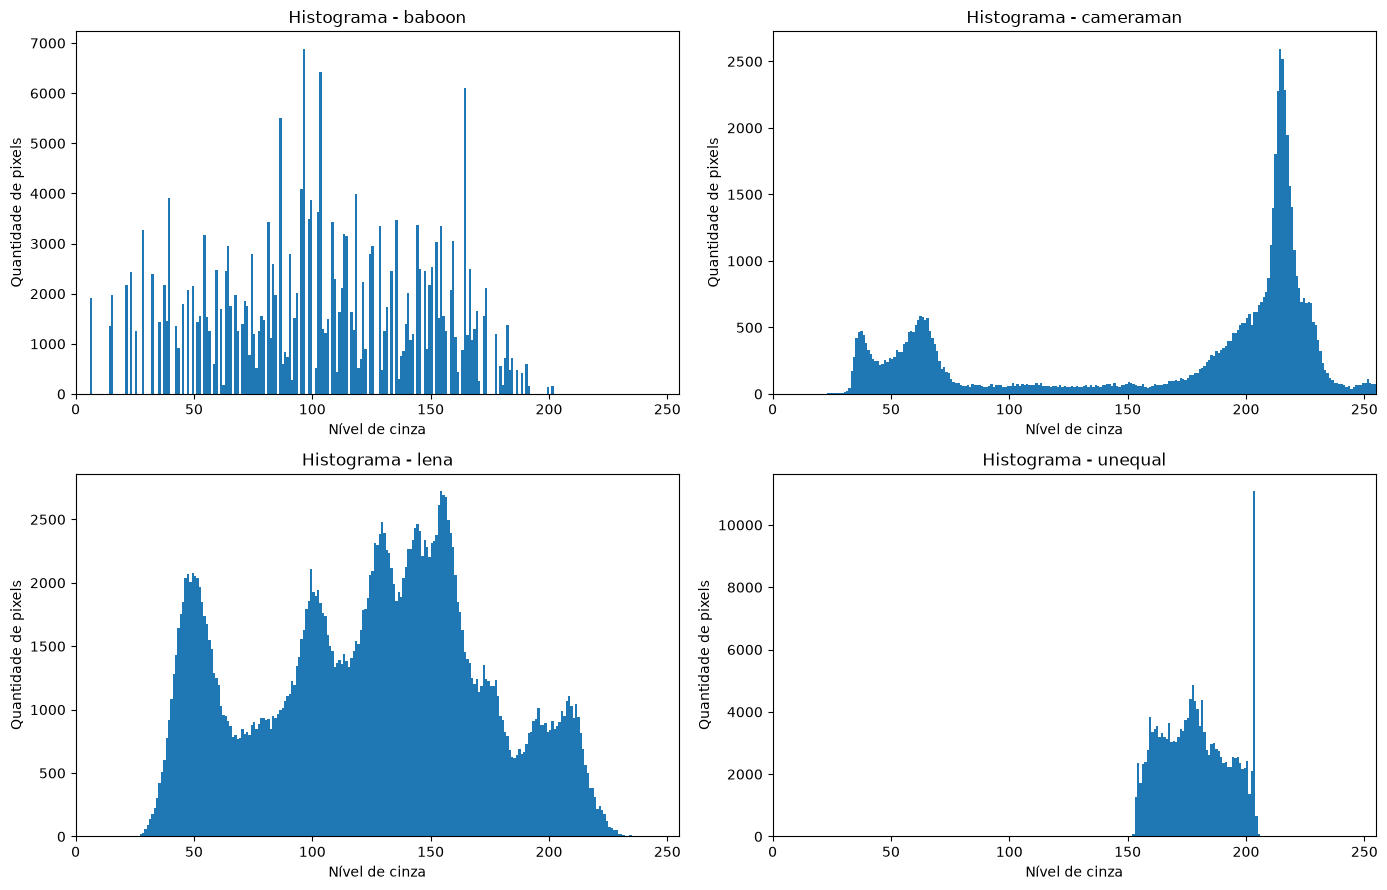

In [105]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

for ax, image_path in zip(axes.ravel(), IMAGE_PATHS):

    # Carrega a imagem
    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    # Verifica se a imagem foi carregada
    if image is None:
        raise FileNotFoundError(
            f"Não foi possível encontrar: {image_path}"
        )

    # Nome da imagem
    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    # Histograma
    ax.hist(
        image.ravel(),
        bins=256,
        range=(0, 256)
    )

    ax.set_title(
        f"Histograma - {image_name}"
    )

    ax.set_xlabel(
        "Nível de cinza"
    )

    ax.set_ylabel(
        "Quantidade de pixels"
    )

    ax.set_xlim(0, 255)

plt.tight_layout()
plt.show()

In [106]:
def image_entropy(image):
    """
    Calcula a entropia de Shannon
    do histograma de uma imagem.
    """

    histogram = np.bincount(
        image.ravel(),
        minlength=256
    )

    probabilities = (
        histogram / histogram.sum()
    )

    probabilities = probabilities[
        probabilities > 0
    ]

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    return entropy

entropy_results = []

for image_path in IMAGE_PATHS:

    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    entropy = image_entropy(image)

    entropy_results.append({
        "Imagem": image_name,
        "Entropia (bits)": entropy
    })

entropy_df = pd.DataFrame(
    entropy_results
)

entropy_df

,Imagem,Entropia (bits)
0,baboon,6.712203
1,cameraman,6.904609
2,lena,7.445507
3,unequal,5.594758


### Interpretação da DCT

Na representação pela DCT, os coeficientes próximos ao canto superior esquerdo correspondem às componentes de menor frequência, enquanto os coeficientes mais afastados representam componentes de frequência espacial mais elevada.

A concentração de energia em determinadas regiões da representação DCT está relacionada à estrutura da imagem. Regiões mais suaves tendem a concentrar energia nas baixas frequências, enquanto detalhes, bordas e texturas contribuem para componentes de frequências mais elevadas.

Essa característica é importante para o método desenvolvido, pois a matriz de quantização possui valores maiores para as posições associadas às frequências mais altas. Dessa forma, essas componentes são quantizadas de maneira mais intensa e tendem a produzir mais coeficientes nulos, favorecendo a codificação RLE.

In [107]:
def get_dct_spectrum(image):
    """
    Calcula a DCT bidimensional da imagem
    para visualização da distribuição de frequência.
    """

    image_float = image.astype(np.float64)

    image_centered = image_float - 128.0

    dct_image = get_2D_dct(
        image_centered
    )

    magnitude = np.log1p(
        np.abs(dct_image)
    )

    return magnitude

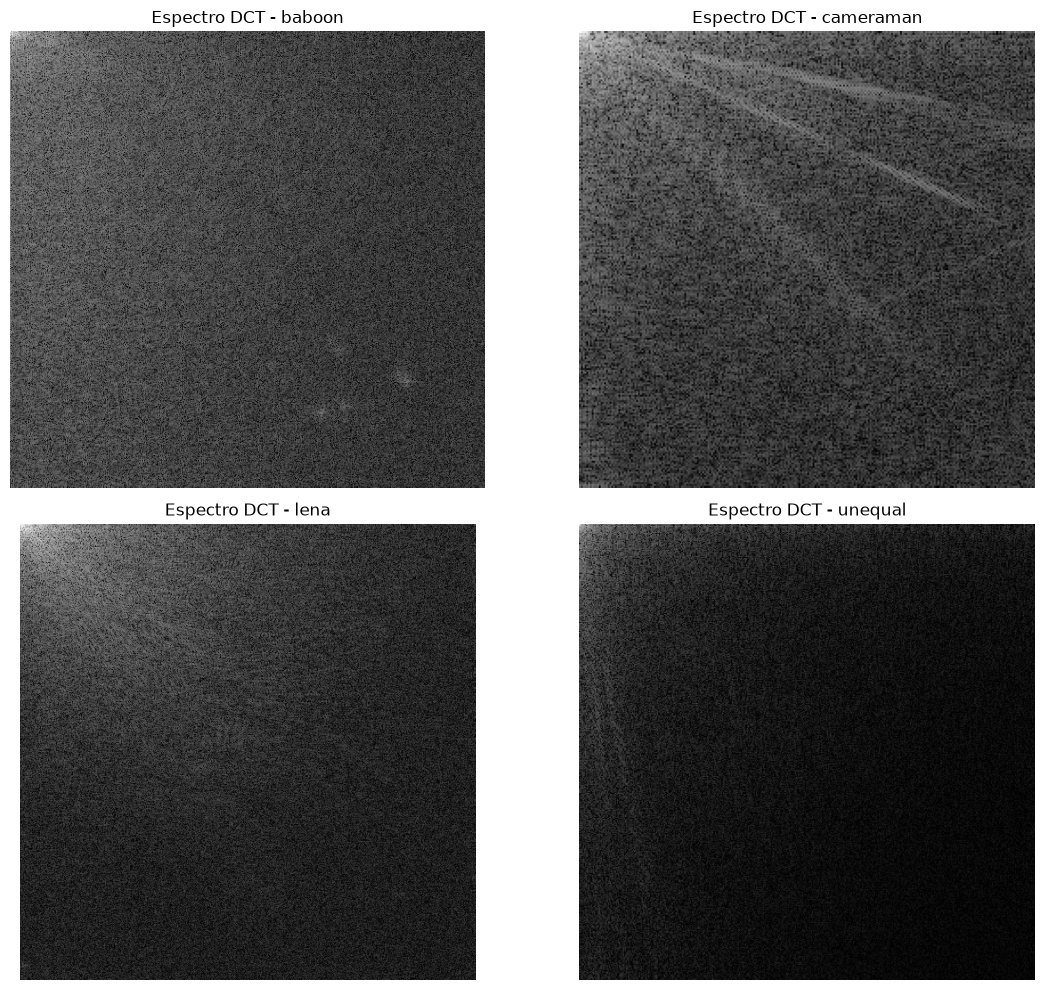

In [108]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10)
)

for ax, image_path in zip(
    axes.ravel(),
    IMAGE_PATHS
):

    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    spectrum = get_dct_spectrum(
        image
    )

    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    ax.imshow(
        spectrum,
        cmap="gray"
    )

    ax.set_title(
        f"Espectro DCT - {image_name}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

### Relação entre as características das imagens e a compressão

A imagem `unequal` apresenta uma distribuição de níveis de cinza diferente das demais imagens analisadas. Como essa característica pode resultar em uma distribuição mais concentrada do histograma, sua entropia pode ser menor, indicando uma quantidade menor de informação necessária para representar estatisticamente os níveis de cinza.

Essa característica também pode influenciar a distribuição dos coeficientes da DCT. Imagens com regiões mais uniformes tendem a concentrar maior parte da energia nas baixas frequências, enquanto detalhes e texturas geram componentes adicionais nas frequências mais altas.

Esse comportamento ajuda a explicar por que uma mesma matriz de quantização pode apresentar taxas de compressão e valores de PSNR bastante diferentes dependendo da imagem de entrada.

# 24. Conclusão

Neste trabalho foi desenvolvido um método de compressão de imagens
baseado em DCT, quantização, varredura zig-zag e RLE.

A DCT foi utilizada para representar a imagem no domínio da frequência,
enquanto a quantização permitiu descartar informações consideradas
menos relevantes para a reconstrução. A varredura zig-zag organizou
os coeficientes de modo a concentrar sequências de zeros, permitindo
sua exploração pela codificação RLE.

O método também implementou a decodificação do arquivo comprimido e
a reconstrução da imagem, permitindo avaliar a qualidade por meio
do RMSE e PSNR e a eficiência por meio da taxa de compressão.

A análise com diferentes matrizes de quantização permitiu observar
o compromisso entre redução do tamanho do arquivo e qualidade da
imagem reconstruída.